Practice 4

Train an SVC(kernel="poly", degree=3) on the moons dataset and add it as a fourth panel next to notebook 3's linear/RBF comparison (section 2.3). Where does its boundary fall between the two?

Cell 1 — Import Required Tools

- Explanation

We import the tools used in the instructor's SVM notebook to create the moons dataset, train SVM models, and visualize their decision boundaries.

In [6]:

# Import the tools needed to create moons data and train SVM models

from sklearn.datasets import make_moons
from sklearn.svm import SVC
import numpy as np
import matplotlib.pyplot as plt

Cell 2 — Create the Moons Dataset

- Explanation

We create the same synthetic moons dataset used in the instructor's SVM notebook so that the new polynomial model is compared under the same conditions.

In [7]:

# Create the synthetic moons dataset used for SVM boundary visualization

X_moons, y_moons = make_moons(
    n_samples=300 , noise=0.25 , random_state=13)

Cell 3 — Create the Boundary Plotting Function

- Explanation

We reuse the instructor's boundary-plotting approach to visualize how each SVM kernel separates the two classes.

In [8]:
# Create a reusable function for visualizing SVM decision boundaries
def plot_boundary(ax, model, X, y, title):
    x_min, x_max = X[:, 0].min() - 0.6, X[:, 0].max() + 0.6
    y_min, y_max = X[:, 1].min() - 0.6, X[:, 1].max() + 0.6

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 300),
        np.linspace(y_min, y_max, 300))

    grid = np.c_[xx.ravel(), yy.ravel()]
    Z = model.predict(grid).reshape(xx.shape)

    ax.contourf(
        xx , yy , Z , levels=[-0.5, 0.5, 1.5] , alpha=0.35)

    ax.contour(
        xx , yy , Z , levels=[0.5] , colors="black" , linewidths=2)

    ax.scatter(
        X[:, 0] , X[:, 1] , c=y , edgecolors="white" , linewidths=0.6 , s=26)

    ax.set_title(title)
    ax.set_xticks([])
    ax.set_yticks([])

Cell 4 — Train the Linear SVM

- Explanation

We train the linear SVM used in the instructor's original moons comparison. This gives us the baseline linear decision boundary.

In [9]:

# Train the linear-kernel SVM used as the baseline comparison

svm_linear_moons = SVC(
    kernel="linear" , C=1
    ).fit(X_moons, y_moons)

Cell 5 — Train the RBF SVM

- Explanation

We train the RBF-kernel SVM from the instructor's comparison. The RBF kernel can create a nonlinear decision boundary for the curved moons dataset.

In [10]:

# Train the RBF-kernel SVM used in the instructor's comparison

svm_rbf_moons = SVC(
    kernel="rbf" , C=1 , gamma="scale"
    ).fit(X_moons, y_moons)

Cell 6 — Train the Polynomial SVM

- Explanation

We add the new polynomial SVM required by Exercise 4. The polynomial kernel uses a degree of 3 exactly as specified in the exercise.

In [12]:

# Train the polynomial-kernel SVM required by Exercise 4

svm_poly_moons = SVC(
    kernel="poly" , degree=3
    ).fit(X_moons, y_moons)

Cell 7 — Compare All Three Decision Boundaries

- Explanation

We place the linear, RBF, and polynomial SVM boundaries side by side so their behavior on the same moons dataset can be compared directly.

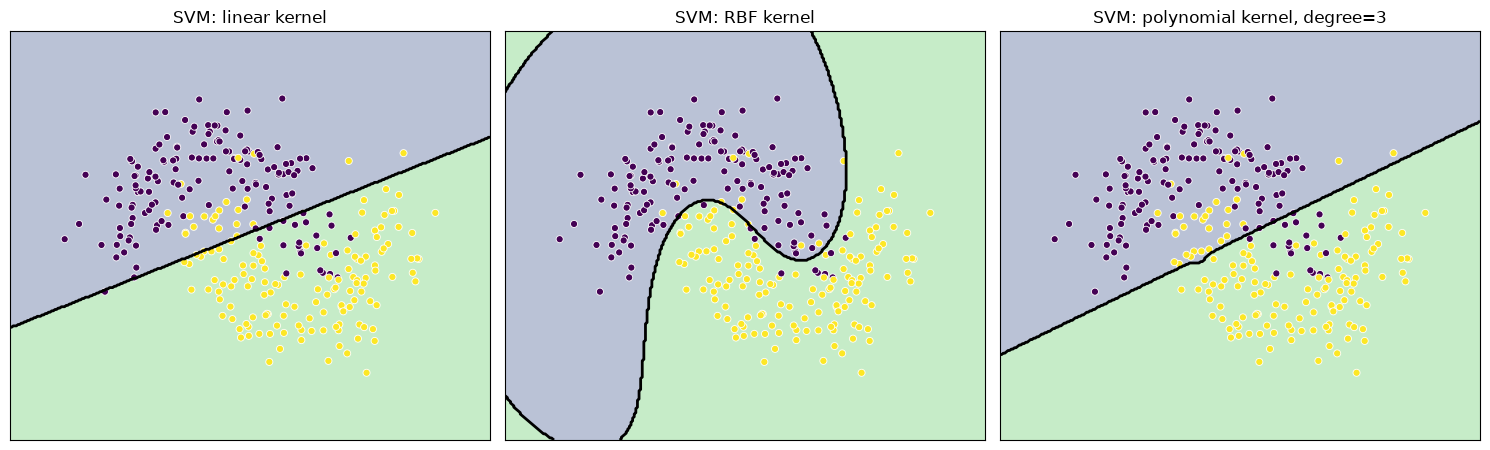

In [13]:

# Compare the decision boundaries of the three SVM kernels

fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))

plot_boundary(
    axes[0] , svm_linear_moons , X_moons , y_moons ,
    "SVM: linear kernel")

plot_boundary(
    axes[1] , svm_rbf_moons , X_moons , y_moons ,
    "SVM: RBF kernel")

plot_boundary(
    axes[2] , svm_poly_moons , X_moons , y_moons ,
    "SVM: polynomial kernel, degree=3")

plt.tight_layout()
plt.show()

Practice 4 — SVM poly kernel

The polynomial-kernel (degree=3) boundary sits between the other two: it curves to follow the moons' shape, unlike the linear kernel's straight line, but it doesn't wrap as tightly around each cluster as the RBF kernel does.

 In practice, the polynomial kernel offers a fixed, global level of curvature 
 (set by its degree), while RBF adapts its curvature locally to the data — making RBF more flexible but also more prone to overfitting on noisy regions.